In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation

Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.00184185567201938
  u_yy: 0.0018545829714941226
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 0.011083025022671887
  u_yy: 0.01146434888539209
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 0.04575102160323976
  u_yy: 0.043167847599276776


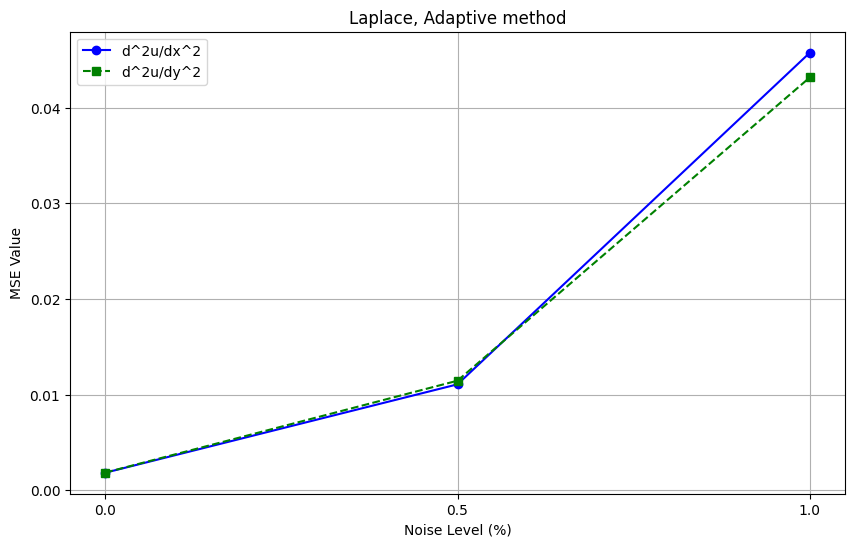

In [4]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Adaptive_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Adaptive_yy_noise{noise}.npy')


    u_xx = u_xx[5:27, 5:27]
    u_yy = u_yy[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_yy = gradient_yy[5:27, 5:27]

    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_yy = calculate_mse(u_yy, gradient_yy)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.0018604661678457994
  u_yy: 0.0018359801690496491
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 0.5938278790224404
  u_yy: 0.5694610769300827
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 2.6707650613078604
  u_yy: 2.610943596423319


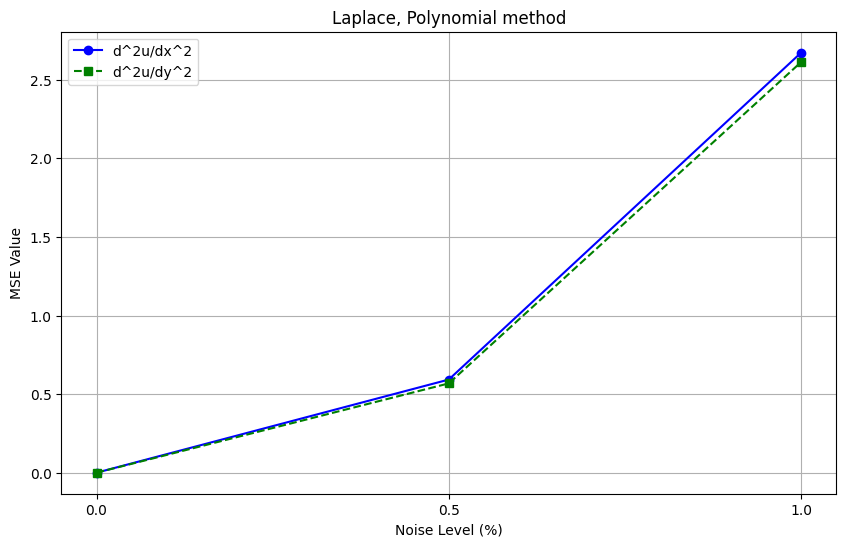

In [5]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Polynomial_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Polynomial_yy_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_yy = u_yy[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_yy = gradient_yy[5:27, 5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_yy = calculate_mse(u_yy, gradient_yy)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 26.535975918831173
  u_yy: 14.152062504511287
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 28.76915544131302
  u_yy: 17.070514358370072
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 38.1629404389328
  u_yy: 25.755507449584393


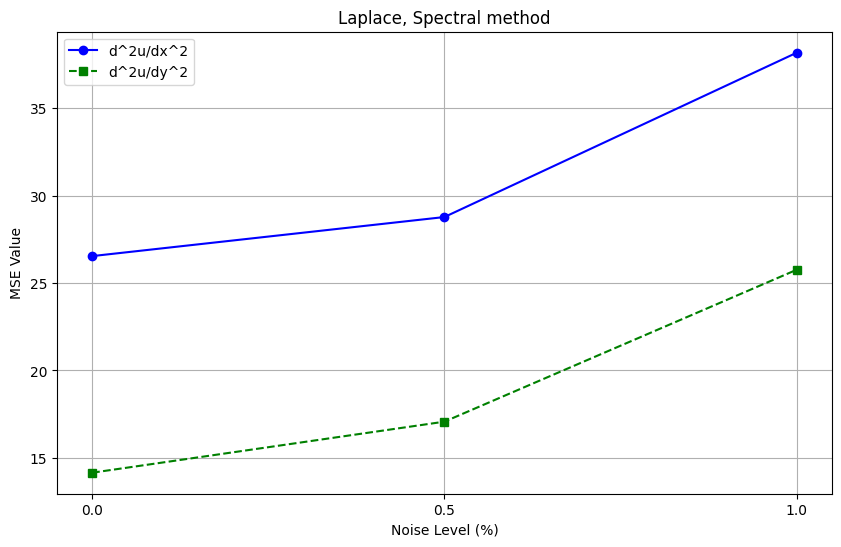

In [6]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Spectral_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Spectral_yy_noise{noise}.npy')
    
    u_xx = u_xx[5:27, 5:27]
    u_yy = u_yy[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_yy = gradient_yy[5:27, 5:27]
    
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_yy = calculate_mse(u_yy, gradient_yy)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.0016765776466054461
  u_yy: 0.007891877973756525
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 72.7556568512505
  u_yy: 2.4132028898928604
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 46.868353587993965
  u_yy: 47.17704150548445


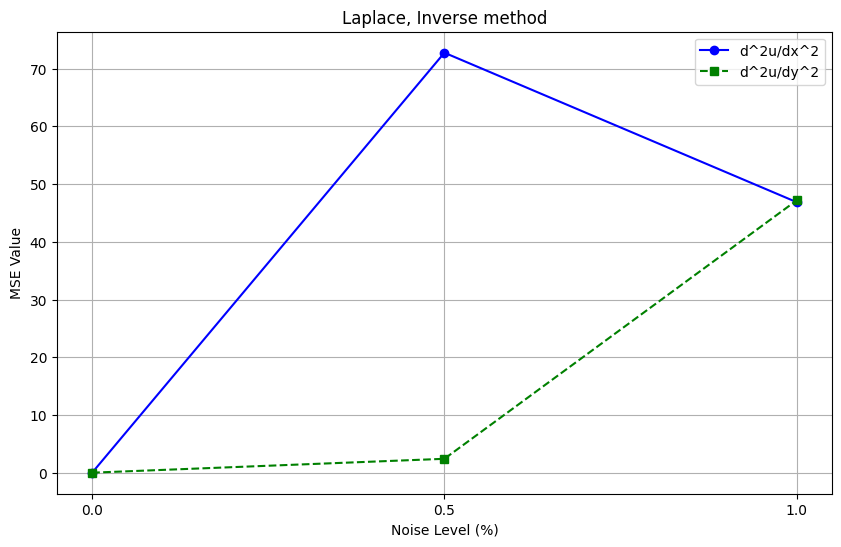

In [9]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Inverse_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Inverse_yy_noise{noise}.npy')
    
    u_xx = u_xx[5:27, 5:27]
    u_yy = u_yy[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_yy = gradient_yy[5:27, 5:27]
    
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_yy = calculate_mse(u_yy, gradient_yy)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.4918821915996714
  u_yy: 0.4863699116659661
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 2.931997622363357
  u_yy: 3.0227170943718864
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 12.080061254030321
  u_yy: 11.388487157201912


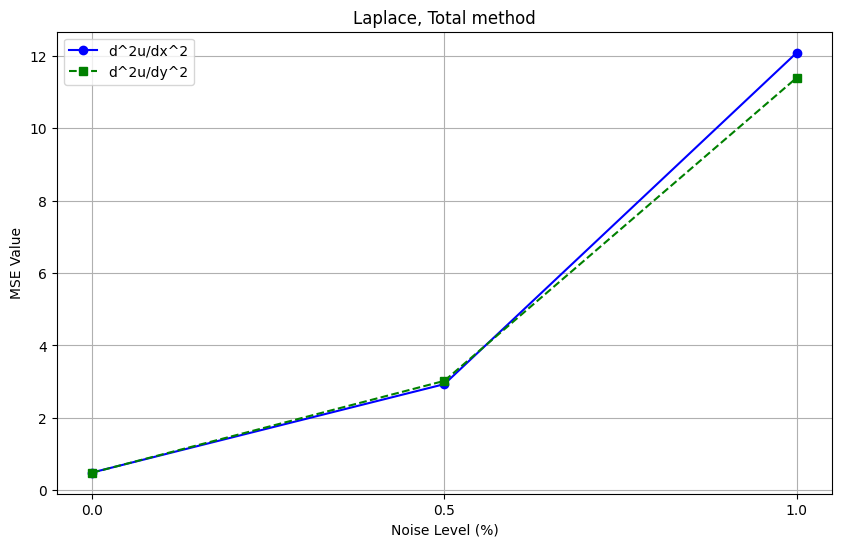

In [3]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Total_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Total_yy_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_yy = u_yy[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_yy = gradient_yy[5:27, 5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_yy = calculate_mse(u_yy, gradient_yy)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Total_error.pdf', format='pdf')
plt.show()


In [4]:
u_xx.shape

(22, 22)